# Financial Data Engineering & Bank-Failure Early Warning
**Nguyễn Lê Nam Khánh · 11230976 · BFT65B, National Economics University**

An auditable FDIC pipeline for extracting, reconciling and analysing financial reports, with a time-ordered risk-ranking model and transparent alert-cost scenarios.

This is the **curated portfolio edition**. Research pilots and debugging cells have been removed. Functions live in `src/fdic_risk/`; this notebook presents the pipeline and its evidence in execution order. Historical development experiments are retained as clearly identified aggregate results. Final fits, storage/processing measurements, Spark checks and the frozen holdout evaluation were executed for this edition.

## 1. Executive findings
The study covers 1,682,616 financial reports, 170 quarters and 87 source fields. These fields are not 87 predictors. The selected B3 procedure uses forward-HGB feature groups plus a four-column loss-buffer block; its final fit has 24 predictors.

On the once-evaluated holdout, B3 does **not** dominate the simpler references: core7+iRF has higher AP. A high proportion of detected failure events also coexists with many false alerts. This notebook reports that trade-off explicitly.

**Decision scope:** support an analyst's offsite-review shortlist, not automatic closure, default probabilities certified for regulation, or a claim of realized cost savings.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config_final.json").exists())
sys.path.insert(0, str(ROOT / "src"))
from fdic_risk.presentation import unpack_results
unpack_results(include_test=True)
TABLES = ROOT / "reports" / "tables"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 4.5), "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
read = lambda name: pd.read_csv(TABLES / name)
load = lambda name: json.loads((TABLES / name).read_text())
config = json.loads((ROOT / "config_final.json").read_text())
policy = json.loads((ROOT / "docs/cost_policy.json").read_text())
test = read("test_metrics.csv")
primary = test[(test.scope == "all_test") & np.isclose(test.q, policy["selected_q"])].copy()
display(primary[["pipeline", "AP_D7", "AP_pooled", "ROC_AUC", "caught_events", "events", "precision", "row_recall", "alerts"]].round(4))

Matplotlib is building the font cache; this may take a moment.


,pipeline,AP_D7,AP_pooled,ROC_AUC,caught_events,events,precision,row_recall,alerts
1,B3,0.2506,0.2538,0.9173,68,78,0.0223,0.8249,9522
8,core7_LR,0.2667,0.2489,0.9570,69,78,0.0222,0.8327,9644
15,core7_iRF,0.3098,0.3113,0.9439,68,78,0.0217,0.8132,9632


## 2. Question, target and information time
The target is failure in `(prediction_as_of, prediction_as_of + 4 quarters]`. A report dated quarter `r` is assumed available at the end of `r+1`. This is a conservative release-lag assumption, not an observed publication timestamp.

Mergers and assistance are not failures. Only the first qualifying FAILURE of a CERT creates its failure label. Observations outside the insured population, already exited institutions, incomplete horizons and unverifiable censoring follow documented exclusion rules. Failure dates and exit evidence are used for labels, never as predictors.

The source provides revised values and a current Institutions snapshot. Historical I01 quarantine was discovered retrospectively. Accordingly, the project is **not a vintage-perfect real-time simulation**.

## 3. Acquisition and storage
`config.yaml` fixes the 87 requested fields and 1984Q1–2026Q2 scope. `scripts/acquire.py` pages through the FDIC API with retry, validates page totals, retains compressed raw JSON responses and writes typed Parquet. Resume requires matching raw/typed hashes and field lists.

Raw files are immutable inputs. Public GitHub deliverables contain code and aggregate evidence only; all bank-level data and fitted models stay ignored.

In [2]:
acquisition = load("acquisition_summary.json")
display(pd.DataFrame([{"financial_rows": acquisition["financial_rows"], "quarters": acquisition["quarters"], "source_fields": acquisition["fields"], "all_quarter_totals_match": acquisition["quarters_match_api_total"], "download_dates": ", ".join(acquisition["download_dates"])}]))
display(read("acquisition_completeness.csv")[["quarter", "rows", "api_total", "complete"]].head(5))

,financial_rows,quarters,source_fields,all_quarter_totals_match,download_dates
0,1682616,170,87,True,2026-11-06


,quarter,rows,api_total,complete
0,19840331,17930,17930,True
1,19840630,17935,17935,True
2,19840930,17946,17946,True
3,19841231,17949,17949,True
4,19850331,17968,17968,True


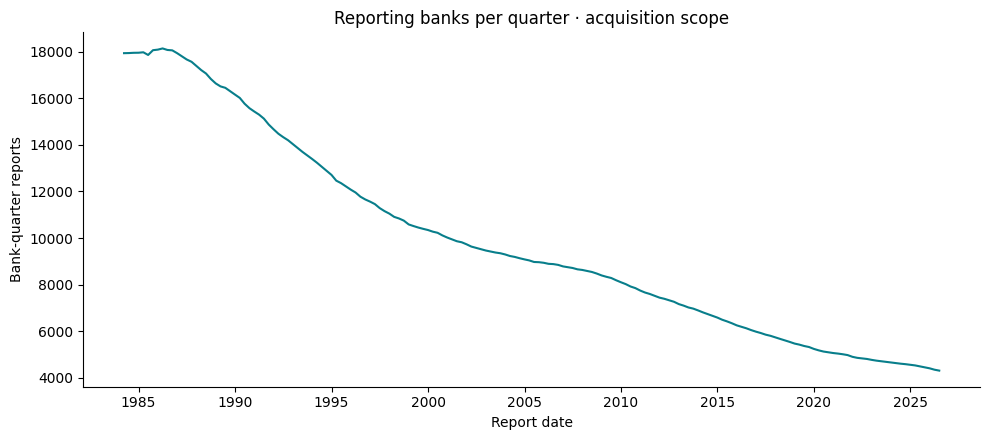

In [3]:
a = read("acquisition_completeness.csv")
fig, ax = plt.subplots()
ax.plot(pd.to_datetime(a.quarter.astype(str)), a.rows, color="#087e8b")
ax.set(title="Reporting banks per quarter · acquisition scope", xlabel="Report date", ylabel="Bank-quarter reports")
fig.tight_layout(); fig.savefig(FIGURES / "reporting_banks.png", dpi=150); plt.show()

## 4. Automated quality checks and financial reconciliation
The quality layer distinguishes true zeros, structurally unavailable ratios, nonpositive denominators, negative but legitimate capital/earnings, unverified negative stocks and suspicious YTD accounting restarts. It records every quarantine instead of deleting all unusual banks.

For YTD flows, exact CERT/calendar-quarter joins replace row shifts. TTM requires four consecutive quarters. Verified accounting identities recover a limited historical window; suspected accounting-basis restarts are quarantined. No successor relationship from a later snapshot is silently used to reconstruct predictors. No future filling or interpolation is performed.

`docs/reconciliation_queries.sql` provides SQL extraction and reconciliation examples. Differences such as `ASSET != LIAB + EQ` are review exceptions, not automatic deletion rules.

In [4]:
display(read("source_quality_profile.csv").sort_values("missing_share", ascending=False).head(10))
display(read("source_quality_flags.csv").sort_values("rows_flagged", ascending=False).head(8))
display(read("zero_rule_summary.csv").sort_values("len", ascending=False).head(10))
display(read("quarantine_summary.csv"))
display(read("missing_source_summary.csv"))

,field,dtype,rows,missing,missing_share,zero,negative
32,P3LNLS,Float64,1350892,971925,0.719469,29133.0,0.0
29,P3ASSET,Float64,1350892,971925,0.719469,28949.0,0.0
51,SCHF,Float64,1350892,727257,0.538353,277072.0,0.0
53,SCAA,Float64,1350892,727257,0.538353,45160.0,0.0
50,SCHA,Float64,1350892,653645,0.483862,290319.0,493.0
52,SCAF,Float64,1350892,653644,0.483861,63926.0,4.0
18,RBC1RWAJ,Float64,1350892,421897,0.312310,26.0,3498.0
23,RWAJT,Float64,1350892,421785,0.312227,111.0,10.0
46,LNREAG,Float64,1350892,192851,0.142758,285767.0,0.0
76,NTRTIME,Float64,1350892,162952,0.120625,15132.0,0.0


,flag,rows_flagged,meaning,scope
16,q_cap_zero_cet1,1350892,"diagnostic exception, not necessarily error",1984Q1-2011Q3
15,q_cap_zero_rbc,428598,"diagnostic exception, not necessarily error",1984Q1-2011Q3
14,q_den_nonpos_EQ,14921,"diagnostic exception, not necessarily error",1984Q1-2011Q3
3,q_neg_equity,14899,"diagnostic exception, not necessarily error",1984Q1-2011Q3
4,q_liab_gt_asset,14819,"diagnostic exception, not necessarily error",1984Q1-2011Q3
11,q_den_nonpos_LNLSGR,13362,"diagnostic exception, not necessarily error",1984Q1-2011Q3
12,q_den_nonpos_DEP,8762,"diagnostic exception, not necessarily error",1984Q1-2011Q3
5,q_dep_gt_asset,5975,"diagnostic exception, not necessarily error",1984Q1-2011Q3


,field,reason,len
3,IDT1CER,zero_not_applicable_regime,1415481
10,RBCRWAJ,zero_den_null,422701
4,IDT1RWAJR,zero_num_input_null_script,79301
11,RBCRWAJ,zero_den_zero,36811
6,LNATRESR,zero_den_zero,18510
2,IDLNCORR,zero_den_zero,15235
9,LNLSDEPR,zero_den_zero,11808
0,EQV,zero_num_null,4032
7,LNATRESR,zero_num_null,3996
1,IDLNCORR,zero_den_null,1244


,policy,feature,len
0,B1,brokered_assets,2
1,Y1,efficiency_ttm,587
2,Y1,nim_ttm,648
3,Y1,provision_loans_ttm,613
4,Y1,roa_ttm,668


,nco_status,len
0,insufficient_history_or_report_gap,69673
1,observed_four_quarter_value,1480709
2,denominator_unavailable_or_nonpositive,36394
3,quarterly_flow_or_quality_policy_missing,629
4,entire_source_window_unavailable,64920
5,incomplete_source_window,8268


### Refactor parity
The curated feature builder was checked against the approved research representation on the same development keys. This verifies the refactor's numerical behavior; it does not prove that every historical reporting value or economic assumption is correct.

In [5]:
parity = read("feature_parity.csv")
assert parity.mismatch_rows.sum() == 0
print(f"{len(parity)} columns checked: zero mismatched development values at the declared tolerance.")
display(parity.head(8))

41 columns checked: zero mismatched development values at the declared tolerance.


,column,mismatch_rows,max_abs_diff
0,CERT,0,NaN
1,report_period_end,0,NaN
2,qi,0,NaN
3,fit_exclude_i01,0,NaN
4,eq_assets,0,0.0
5,noncurrent_loans,0,0.0
6,reserve_loans,0,0.0
7,roa_ttm,0,0.0


## 5. Scalable processing: measured comparisons
Storage measurements use the same 7-column projection and 1984Q1–2011Q3 rows, not the full 87-field table. The pandas and Polars queries perform the same exact-quarter self-join, financial ratios and quarterly aggregation. Three repetitions are summarized by the median; reads use a warm OS cache.

Polars exposes projection pushdown, lazy planning and parallel execution. Spark reproduces the same calculation locally; numerical reconciliation checks precede performance interpretation. Spark is **not assumed faster** on this laptop-sized dataset.

In [6]:
storage = load("storage_sizes.json")
display(pd.DataFrame([storage])[["rows", "columns", "csv_bytes", "parquet_zstd_bytes", "ratio_csv_to_parquet"]].round(2))
bench = read("storage_processing_benchmarks.csv")
display(bench[["operation", "median_seconds", "runs"]].round(3))

,rows,columns,csv_bytes,parquet_zstd_bytes,ratio_csv_to_parquet
0,1350892,7,68563928,18049411,3.8


,operation,median_seconds,runs
0,pandas CSV full read,0.306,3
1,pandas Parquet full read,0.058,3
2,Polars Parquet full read,0.022,3
3,Polars Parquet projected read,0.005,3
4,Polars lazy scan + exact-quarter join + ratios...,0.073,3
5,pandas scan + exact-quarter join + ratios + ag...,0.569,3


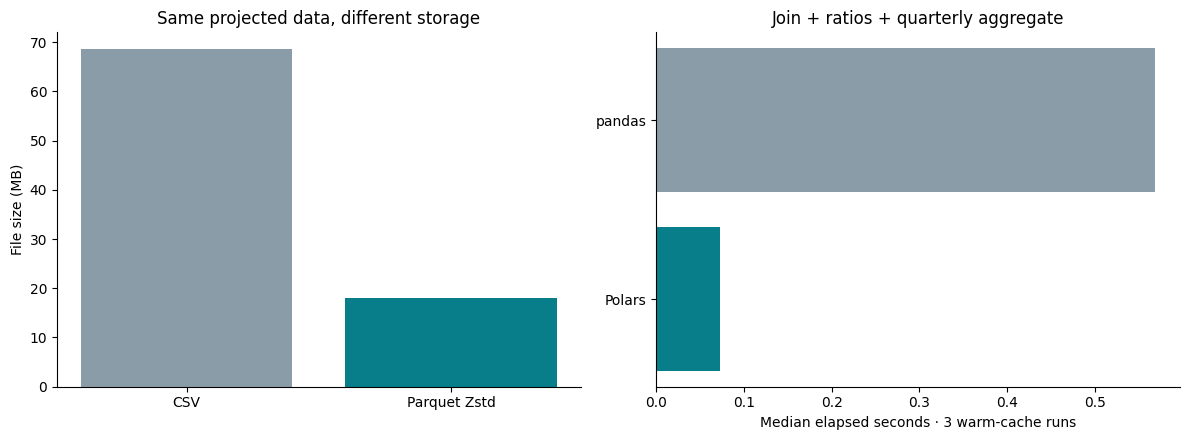

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(["CSV", "Parquet Zstd"], [storage["csv_bytes"]/1e6, storage["parquet_zstd_bytes"]/1e6], color=["#8b9ca9", "#087e8b"])
axes[0].set(title="Same projected data, different storage", ylabel="File size (MB)")
q = bench[bench.operation.str.contains("join")]
axes[1].barh(q.operation.str.replace(" scan + exact-quarter join + ratios + aggregate", "", regex=False).str.replace(" lazy", "", regex=False), q.median_seconds, color=["#087e8b", "#8b9ca9"])
axes[1].set(title="Join + ratios + quarterly aggregate", xlabel="Median elapsed seconds · 3 warm-cache runs")
fig.tight_layout(); fig.savefig(FIGURES / "storage_processing.png", dpi=150); plt.show()

In [8]:
display(read("spark_parity.csv"))
spark_demo = load("spark_mllib_demo.json")
display(pd.DataFrame([{k: spark_demo[k] for k in ["spark_version", "master", "spark_query_seconds_startup_excluded", "validation_year", "validation_rows", "positive_rows", "AP", "ROC_AUC"]}]).round(4))
print("Polars plan excerpt:\n", (ROOT / "reports/polars_plan.txt").read_text()[:1100])
print("Spark plan excerpt:\n", (ROOT / "reports/spark_plan.txt").read_text()[:1100])

,column,match,max_abs_diff
0,rows,True,0.000000e+00
1,eq_assets,True,5.329071e-14
2,npl,True,9.769963e-15
3,flow,True,0.000000e+00


,spark_version,master,spark_query_seconds_startup_excluded,validation_year,validation_rows,positive_rows,AP,ROC_AUC
0,4.3.0,local[2],2.9428,2011,29834,269,0.1925,0.9633


Polars plan excerpt:
 SORT BY [col("REPDTE")]
  AGGREGATE[maintain_order: false]
    [len().alias("rows"), col("eq_assets").mean(), col("npl").mean(), col("flow").sum()] BY [col("REPDTE")]
    FROM
    simple π 4/4 ["REPDTE", "eq_assets", "npl", ... 1 other column]
       WITH_COLUMNS:
       [when(col("ASSET") > 0.0).then((100.0 * col("EQ")) / col("ASSET")).otherwise(null.cast(Float64)).alias("eq_assets"), when(col("LNLSGR") > 0.0).then((100.0 * col("NCLNLS")) / col("LNLSGR")).otherwise(null.cast(Float64)).alias("npl"), when(col("REPDTE").str.slice([dyn int: 4, dyn int: 2]) == "03").then(col("NETINC")).otherwise(col("NETINC") - col("prev_netinc")).alias("flow")] 
        simple π 7/7 ["REPDTE", "ASSET", "EQ", ... 4 other columns]
          LEFT JOIN:
          LEFT PLAN ON: [col("CERT"), col("qi")]
            CACHE[id: 39194631-d4b7-470a-8cc6-e9525fa7cce3]
               WITH_COLUMNS:
               [((col("REPDTE").str.slice([dyn int: 0, dyn int: 4]).strict_cast(Int64) * 4) + ((col(

Spark MLlib is a separate, time-ordered LR demonstration: fit through 2009, evaluate 2011; train-fitted approximate median, vector assembly, scaling and regularized logistic regression. Its preprocessing and penalty differ from sklearn, so it is not presented as a matched estimator comparison.

**When would a cluster help?** The full acquired panel is feasible locally. A cluster becomes a candidate when wider transactional joins, repeated multi-entity workloads, concurrency or memory exceed the measured laptop capacity. The local experiment does not establish a universal row-count or speed threshold for a cluster.

## 6. Feature contracts and train-only preprocessing
The research path started with 87 source fields, screened them economically and technically, then built 21 economic feature groups. Groups contain levels, TTM measures and exact four-quarter changes. Forward-HGB selected groups on each outer-train window; the four loss-buffer features were subsequently added as an adaptive hypothesis (B3).

The final dev-only selection contains 12 original groups / 20 columns plus the four T columns. Selection on final dev is a **refit of the selected procedure**, not an independent validation of that exact set.

`ContractCapperV4 → train median → iRF` preserves the tested recipe. LR adds StandardScaler. Cap/no-cap and missing-indicator branches were investigated; their results do not establish that indicators or uncapped trees are universally useless. Structural nulls remain explicit in quality ledgers even when a median is used at model input.

In [9]:
contracts = read("final_feature_contracts.csv")
display(contracts[["feature", "formula"]])
print("Final B3 predictors:", len(config["B3_columns"]))
print("Excluded from X: CERT, outcome dates, labels, exit evidence and retrospective audit flags.")

,feature,formula
0,eq_assets,100 * EQ / ASSET
1,noncurrent_loans,100 * NCLNLS / LNLSGR
2,roa_ttm,100 * sum(last 4 quarterly NETINC flows) / ASSET
3,nim_ttm,100 * sum4(INTINC_flow - EINTEXP_flow) / ASSET
4,provision_loans_ttm,100 * sum4(ELNATR_flow) / LNLSGR
5,ore_assets,100 * ORE / ASSET
6,npa_assets,100 * (NCLNLS + ORE) / ASSET
7,cd_assets,100 * LNRECONS / ASSET
8,cre_assets,100 * LNRENRES / ASSET
9,multifam_assets,100 * LNREMULT / ASSET


Final B3 predictors: 24
Excluded from X: CERT, outcome dates, labels, exit evidence and retrospective audit flags.


## 7. Time-ordered validation and feature-selection evidence
Historical evaluation uses 64 folds: 16 validation years (1996–2011) under fixed-origin, expanding, rolling-5-year and rolling-10-year schemes. Identical training windows can share fits, giving 49 distinct outer-train groups. Selection and tuning occur only inside outer-train, with label maturity enforced and a four-quarter gap.

Forward, backward, floating selection, GA, stepwise logit, mRMR, stability selection and certified group lasso were explored. The unconverged original group-lasso branch is excluded. These historical investigations are preserved as evidence, rather than rerun or silently relabelled as new results.

AP-D7 is the equal-year mean over years with positive rows. The adaptive D43 minimax rule combines AP-D7 and unique-event recall at a reference 5% budget across fixed-origin/rolling-5y. It is a disclosed preference rule, not a theorem that 5% is optimal. The inner selector still optimizes AP, not a multi-objective loss.

In [10]:
folds = read("split_inner_folds.csv")
folds = folds[folds.candidate == "A_recent"]
display(folds.groupby("scheme").agg(folds=("val_year", "size"), first_year=("val_year", "min"), last_year=("val_year", "max")))
print("Total validation folds:", len(folds))
for name in ["exp3d_fs1_d7.csv", "exp3d_fs1_mmr.csv"]:
    if (TABLES / name).exists():
        print(name)
        selected_table = read(name)
        if "pipeline" in selected_table:
            selected_table = selected_table[~selected_table.pipeline.str.startswith("glasso|", na=False)]
        display(selected_table.head(10))

,folds,first_year,last_year
scheme,,,
expanding,16,1996,2011
fixed_origin,16,1996,2011
rolling_10y,16,1996,2011
rolling_5y,16,1996,2011


Total validation folds: 64
exp3d_fs1_d7.csv


,pipeline,expanding,fixed_origin,rolling_10y,rolling_5y,expanding_complete,fixed_origin_complete,rolling_10y_complete,rolling_5y_complete,fs_score,units_mean
0,mrmr_full|lr,0.559437,0.234886,0.420064,0.182211,True,True,True,True,0.208548,8.62500
1,mrmr_hgb|lr,0.555379,0.234886,0.420064,0.177775,True,True,True,True,0.206330,8.68750
2,fwd_hgb|lr,0.550508,0.217475,0.278446,0.185924,True,True,True,True,0.201699,7.46875
3,core7|lr,0.571023,0.221810,0.460232,0.179759,True,True,True,True,0.200785,7.00000
4,stab_l1|lr,0.552892,0.200694,0.363062,0.172565,True,True,True,True,0.186630,15.84375
5,sffs_hgb|lr,0.536123,0.210881,0.391495,0.156251,True,True,True,True,0.183566,7.34375
6,fwd_hgb|hgb,0.585345,0.223511,0.212881,0.142730,True,True,True,True,0.183120,7.46875
7,ga_hgb|lr,0.559655,0.199574,0.375768,0.160141,True,True,True,True,0.179858,10.96875
8,all21|lr,0.552892,0.200694,0.365565,0.156627,True,True,True,True,0.178660,21.00000
9,bwd_hgb|lr,0.548790,0.198009,0.403103,0.156365,True,True,True,True,0.177187,6.50000


## 8. Model comparisons and what did not improve performance
LR/HGB, Elastic-Net, EBM, RuleFit, kernel approximations and iRF were compared at different research stages. Sample-based FM1 results are not mixed with full-train FT1 results. GRU remained a pilot. Extended feature selection (B8) and nested-tuned XGBoost did not establish an overall improvement over B3 under the registered comparison.

The v65 comparison has 17 outer trains / 32 validation folds for fixed-origin and rolling-5y. XGBoost classifier and ranker each use 12 configurations selected on time-ordered inner sklearn AP. XGBoost's internal MAP is not substituted for sklearn AP.

Historical FM1 sample-only comparison: same positive + 20% negative training sample; do not mix with full-train scores below.


scheme,fixed_origin,rolling_5y
pipeline,,
fwd_hgb|ebm_main,0.2227,0.1457
fwd_hgb|ebm_pair,0.2250,0.1429
fwd_hgb|hgb,0.2196,0.1556
fwd_hgb|irf,0.2394,0.2035
fwd_hgb|kernel,0.1718,0.0645
fwd_hgb|lr,0.1977,0.1845
fwd_hgb|rulefit,0.2019,0.1638


,branch,scheme,ap_d7,caught_5,precision_5,row_recall_5
0,B0,fixed_origin,0.2428,477,0.0541,0.7905
1,B1,fixed_origin,0.2196,481,0.0527,0.7880
2,B2,fixed_origin,0.2462,480,0.0550,0.8036
3,B3,fixed_origin,0.2481,481,0.0549,0.8031
7,XGBc_tuned|core7T,fixed_origin,0.2409,482,0.0538,0.8067
11,XGBr_tuned|core7T,fixed_origin,0.2305,477,0.0532,0.7925
12,B0,rolling_5y,0.2071,482,0.0526,0.7824
13,B1,rolling_5y,0.1978,484,0.0508,0.7592
14,B2,rolling_5y,0.2019,483,0.0532,0.7940
15,B3,rolling_5y,0.2133,488,0.0547,0.8152


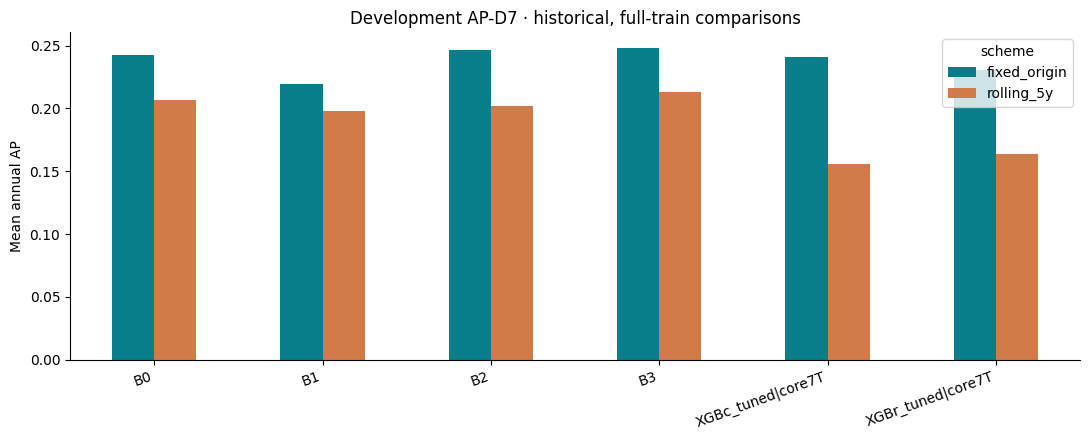

In [11]:
fm = read("exp3d_fm1_d7.csv")
print("Historical FM1 sample-only comparison: same positive + 20% negative training sample; do not mix with full-train scores below.")
display(fm[fm.pipeline.str.startswith("fwd_hgb|")].pivot(index="pipeline", columns="scheme", values="d7").round(4))
v65 = read("v65_branch_scores.csv")
branches = ["B0", "B1", "B2", "B3", "XGBc_tuned|core7T", "XGBr_tuned|core7T"]
compare = v65[v65.branch.isin(branches)]
display(compare[["branch", "scheme", "ap_d7", "caught_5", "precision_5", "row_recall_5"]].round(4))
pivot = compare.pivot(index="branch", columns="scheme", values="ap_d7").reindex(branches)
ax = pivot.plot.bar(color=["#087e8b", "#d17b49"], figsize=(11, 4.5))
ax.set(title="Development AP-D7 · historical, full-train comparisons", ylabel="Mean annual AP", xlabel="")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.savefig(FIGURES / "model_comparison.png", dpi=150); plt.show()

## 9. Class imbalance and performance across periods
Event recall can be high when the model flags just one of a failing bank's positive quarters. AP also reflects how positive bank-quarters rank throughout the list. These are complementary outcomes.

AP also depends on prevalence. A quiet-period AP is not directly comparable to crisis-period AP without reporting class composition; calibration alone does not fix ranking. The project retains raw AP and operational metrics rather than changing evaluation definitions to make values higher.

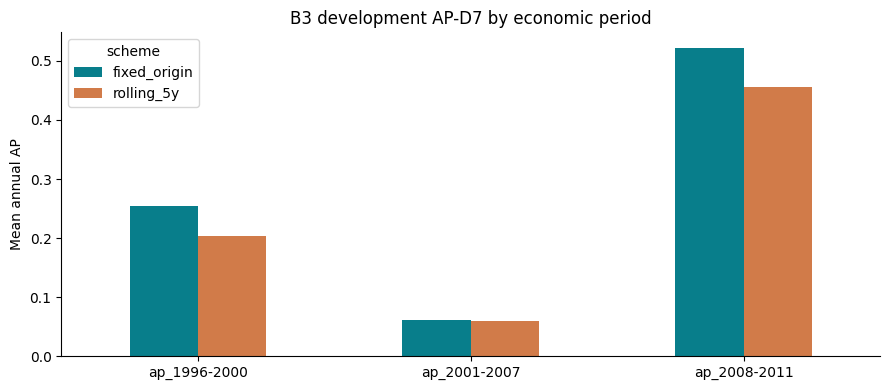

,year,rows,positive_rows,positive_rate,events_with_eligible_window
0,1996,46439,9,0.000194,6
1,1997,44304,10,0.000226,4
2,1998,42416,22,0.000519,11
3,1999,40980,32,0.000781,14
4,2000,39941,22,0.000551,9
5,2001,38762,39,0.001006,14
6,2002,37675,18,0.000478,8
7,2003,36883,19,0.000515,6
8,2004,36075,1,0.000028,1
9,2005,35324,0,0.000000,0


In [12]:
periods = compare[compare.branch == "B3"][["scheme", "ap_1996-2000", "ap_2001-2007", "ap_2008-2011"]].set_index("scheme")
periods.T.plot.bar(color=["#087e8b", "#d17b49"], figsize=(9, 4))
plt.title("B3 development AP-D7 by economic period"); plt.ylabel("Mean annual AP"); plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIGURES / "period_AP.png", dpi=150); plt.show()
years = read("dev_event_counts_by_year.csv")
display(years[years.scheme == "fixed_origin"][["year", "rows", "positive_rows", "positive_rate", "events_with_eligible_window"]])

## 10. Costs, alert chains and a frozen policy scenario
The action is an offsite desk review. Every reviewed alert costs work, including a true alert. A continuous quarterly alert is a repeat review; a missed/non-alerted quarter starts a new file next time. This cold-start/reset rule is an assumption.

`Loss(q) = 110 × 4 × (new_files + 0.5 × repeat_reviews) / 1000 + alpha × missed_event_severity_kUSD2012`.

Each missed event is counted once. Zero COST stays zero; missing severity uses a dev-only median. Latest revised COST and CPI are retrospective descriptors, not costs known to supervisors at the historical decision date.

**Evidence vs assumptions:** OCC's USD110/hour special-examination fee is a proxy, not measured FDIC labour cost. FDIC OIG interview statements motivate 4/12-hour scenarios, not a population average. Repeat effort, productive time, escalation and avoidable-loss fraction are unobserved. The primary `alpha=0.001`, 4 hours and repeat fraction 0.5 are declared illustrative choices, not estimated causal effectiveness.

The final policy minimizes the declared scenario loss over a stated finite q grid on fixed-origin dev predictions; rolling-5y is a sensitivity check. No claim of continuous/global or universally optimal threshold is made. No probability cutoff formula is applied to uncalibrated iRF scores.

,scheme,alpha,q,caught_events,events,hours,peak_quarter_hours,loss_kusd_2012
0,fixed_origin,0.0000,0.0000,0,514,0.0,0.0,0.0000
1,fixed_origin,0.0000,0.0000,0,514,0.0,0.0,741.4482
2,fixed_origin,0.0001,0.0050,300,514,8068.0,236.0,3490.5326
3,fixed_origin,0.0010,0.0353,473,514,53398.0,1664.0,13108.3656
4,fixed_origin,0.0100,0.1500,493,514,212718.0,7080.0,47231.4776
5,fixed_origin,0.1000,1.0000,514,514,1217958.0,47328.0,133975.3800
6,rolling_5y,0.0000,0.0000,0,514,0.0,0.0,0.0000
7,rolling_5y,0.0000,0.0000,0,514,0.0,0.0,741.4482
8,rolling_5y,0.0001,0.0100,343,514,16966.0,472.0,4020.6205
9,rolling_5y,0.0010,0.0353,471,514,56658.0,1664.0,10795.1005


Frozen primary q: 0.0353 | scenario alpha: 0.001


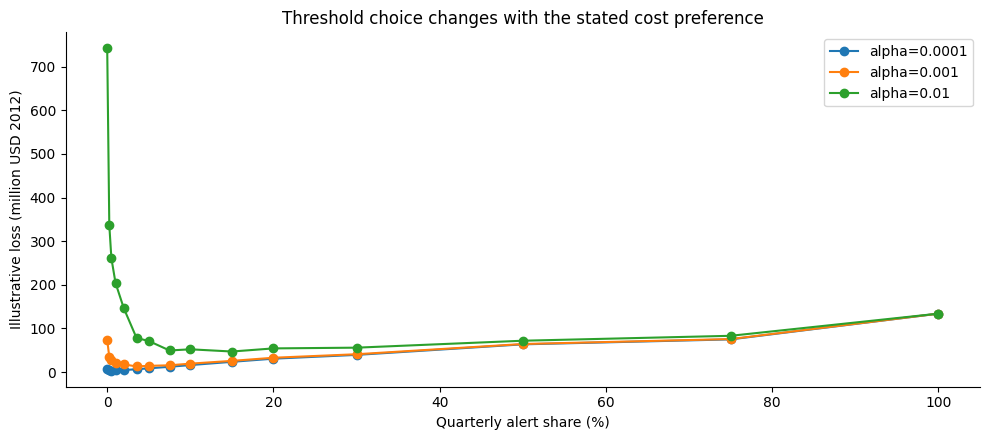

In [13]:
costs = read("cost_scenarios.csv")
winners = costs.sort_values(["loss_kusd_2012", "alerts", "q"]).groupby(["scheme", "alpha"], as_index=False).first()
display(winners[["scheme", "alpha", "q", "caught_events", "events", "hours", "peak_quarter_hours", "loss_kusd_2012"]].round(4))
print("Frozen primary q:", policy["selected_q"], "| scenario alpha:", policy["alpha_primary"])
fig, ax = plt.subplots()
for alpha in [.0001, .001, .01]:
    z = costs[(costs.scheme == "fixed_origin") & np.isclose(costs.alpha, alpha)]
    ax.plot(z.q*100, z.loss_kusd_2012/1000, marker="o", label=f"alpha={alpha:g}")
ax.set(xlabel="Quarterly alert share (%)", ylabel="Illustrative loss (million USD 2012)", title="Threshold choice changes with the stated cost preference")
ax.legend(); fig.tight_layout(); fig.savefig(FIGURES / "cost_sensitivity.png", dpi=150); plt.show()

Escalation is a separate uncertain increment, not silently priced as a full onsite exam for every alert. Capacity scenarios convert paid hours to productive hours allocated to this task. Historical peak load is reported; it is not a future capacity guarantee. We do not tune cost assumptions to obtain a desirable alert budget or model winner.

In [14]:
display(read("escalation_sensitivity.csv"))
workload = read("test_workload_sensitivity.csv")
display(workload[(workload.pipeline == "B3") & np.isclose(workload.q, policy["selected_q"]) & (workload.h_new == 4) & (workload.repeat_fraction == .5)][["FTE", "available_hours_scenario", "mean_hours", "peak_hours", "quarters_over_capacity", "quarters"]].round(2))

,new_file_escalation_probability_scenario,hours_per_escalation_proxy,expected_extra_hours_per_new_file,scope_limit
0,0.00,335,0.00,OIG onsite-exam benchmark for banks up to USD1...
1,0.00,1820,0.00,OIG onsite-exam benchmark for banks up to USD1...
2,0.01,335,3.35,OIG onsite-exam benchmark for banks up to USD1...
3,0.01,1820,18.20,OIG onsite-exam benchmark for banks up to USD1...
4,0.05,335,16.75,OIG onsite-exam benchmark for banks up to USD1...
5,0.05,1820,91.00,OIG onsite-exam benchmark for banks up to USD1...


,FTE,available_hours_scenario,mean_hours,peak_hours,quarters_over_capacity,quarters
28,1,195.0,460.08,988.0,50,50
29,2,390.0,460.08,988.0,41,50
30,4,780.0,460.08,988.0,1,50
31,8,1560.0,460.08,988.0,0,50


## 11. Final fit and one-time holdout evaluation
The selected B3 procedure and two predeclared controls were fitted on dev as-of dates through 2011Q4, with all training labels matured by 2012-12-31. The final feature set is the dev-only selection B plus the T block. Models, schemas, seeds, preprocessing, policy and SHA hashes were frozen before constructing test features.

The user authorized one evaluation in this independent edition. The holdout is as-of 2013Q1–2025Q2. The gap year 2012 is not used to fit the models or backfill alert state. Reopening this notebook **replays saved aggregate outputs**.

A technical pre-prediction count check first stopped because the locked key universe also contained out-of-population/censored observations. Applying the pre-existing nonnull-label rule reconciled the cohort. No score had been produced and no model or policy changed during that technical resume.

In [15]:
display(pd.DataFrame([json.loads((TABLES / "test_population_reconciliation.json").read_text())]))
display(primary[["pipeline", "q", "AP_D7", "AP_pooled", "ROC_AUC", "TP", "FP", "FN", "TN", "precision", "row_recall", "event_recall", "lead_median_quarters"]].round(4))
run_manifest = json.loads((TABLES / "test_run_manifest.json").read_text())
print("Scoring passes:", run_manifest["test_passes"], "| rows:", run_manifest["rows"], "| positive rows:", run_manifest["positive_rows"])

,excluded_unlabelled_or_out_of_population,labelled_evaluation_rows,locked_key_universe,rule
0,6404,273863,280267,registered y_audit-not-null; no score-based ex...


,pipeline,q,AP_D7,AP_pooled,ROC_AUC,TP,FP,FN,TN,precision,row_recall,event_recall,lead_median_quarters
1,B3,0.0353,0.2506,0.2538,0.9173,212,9310,45,264296,0.0223,0.8249,0.8718,3.2526
8,core7_LR,0.0353,0.2667,0.2489,0.9570,214,9430,43,264176,0.0222,0.8327,0.8846,3.2635
15,core7_iRF,0.0353,0.3098,0.3113,0.9439,209,9423,48,264183,0.0217,0.8132,0.8718,3.2526


Scoring passes: 1 | rows: 273863 | positive rows: 257


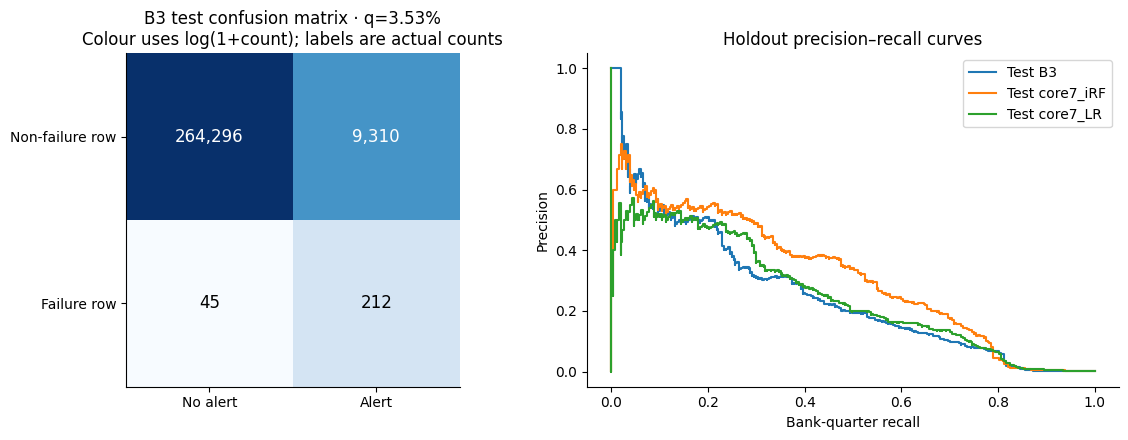

In [16]:
b3 = primary[primary.pipeline == "B3"].iloc[0]
cm = np.array([[b3.TN, b3.FP], [b3.FN, b3.TP]], dtype=int)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].imshow(np.log1p(cm), cmap="Blues")
for i in range(2):
    for j in range(2): axes[0].text(j, i, f"{cm[i,j]:,}", ha="center", va="center", color="white" if np.log1p(cm[i,j])>9 else "black", fontsize=12)
axes[0].set(xticks=[0,1], yticks=[0,1], xticklabels=["No alert", "Alert"], yticklabels=["Non-failure row", "Failure row"], title=f"B3 test confusion matrix · q={b3.q:.2%}\nColour uses log(1+count); labels are actual counts")
curves = read("pr_curve_display.csv")
for name, z in curves[curves.series.str.startswith("Test")].groupby("series", sort=False): axes[1].step(z.recall, z.precision, where="post", label=name)
axes[1].set(xlabel="Bank-quarter recall", ylabel="Precision", title="Holdout precision–recall curves")
axes[1].legend(); fig.tight_layout(); fig.savefig(FIGURES / "holdout_results.png", dpi=150); plt.show()

In [17]:
display(test[(test.scope != "all_test") & (test.pipeline == "B3")][["scope", "rows", "positive_rows", "AP_D7", "precision", "row_recall", "caught_events", "events", "event_recall"]].round(4))
display(read("test_cost_scenarios.csv").query("pipeline == 'B3'").round(4))

,scope,rows,positive_rows,AP_D7,precision,row_recall,caught_events,events,event_recall
4,2013-2019,169500,211,0.2944,0.0328,0.9194,64,67,0.9552
5,2020-2022,58902,21,0.3707,0.0039,0.3810,4,8,0.5000
6,2023-2025,45461,25,0.0684,0.0064,0.4000,4,9,0.4444


,pipeline,q,review_cost_kusd_2012,missed_severity_kusd_2012,unknown_missed_events,fixed_dev_unknown_value_kusd,scenario_loss_kusd_2012,break_even_alpha_vs_never,note
0,B3,0.0100,746.90,2.615300e+07,0,43523.6237,26899.8962,0.0002,retrospective severity-weighted scenario; not ...
1,B3,0.0353,2530.44,2.614082e+07,0,43523.6237,28671.2553,0.0007,retrospective severity-weighted scenario; not ...
2,B3,0.0500,3562.02,2.614082e+07,0,43523.6237,29702.8353,0.0009,retrospective severity-weighted scenario; not ...
3,B3,0.1000,6967.18,2.614082e+07,0,43523.6237,33107.9953,0.0018,retrospective severity-weighted scenario; not ...


**Interpretation:** B3 is the preselected model, not the holdout winner. Core7+iRF has higher holdout AP-D7; LR detects one additional unique event at the primary budget. B3 still produces many false alerts. No model is reselected, tuned or relabelled after seeing this comparison. The study supports an auditable review tool, not a production-readiness claim.

## 12. Explainability: what the fitted model uses
The custom imodels forest is explained using exact path-dependent Tree SHAP on its actual tree arrays and training cover. Toy brute-force comparisons and final additivity checks validate the implementation. These attributions explain probabilities after cap/median preprocessing, not unobserved missing values or causal economic effects.

The SHAP overview uses 96 uniformly sampled development training rows; ALE uses 20,000 training rows. These are **in-sample model descriptions**, not independent evidence of generalization. ALE is used in place of a broad PDP grid to reduce unsupported combinations of correlated financial ratios.

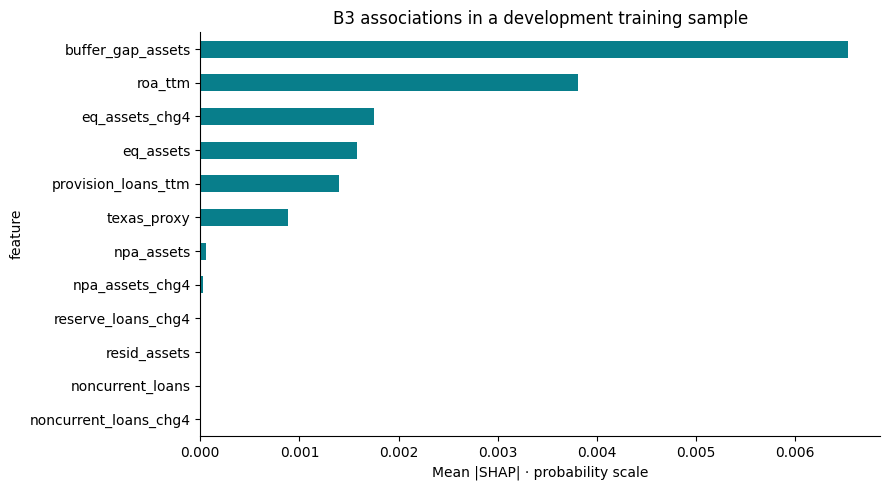

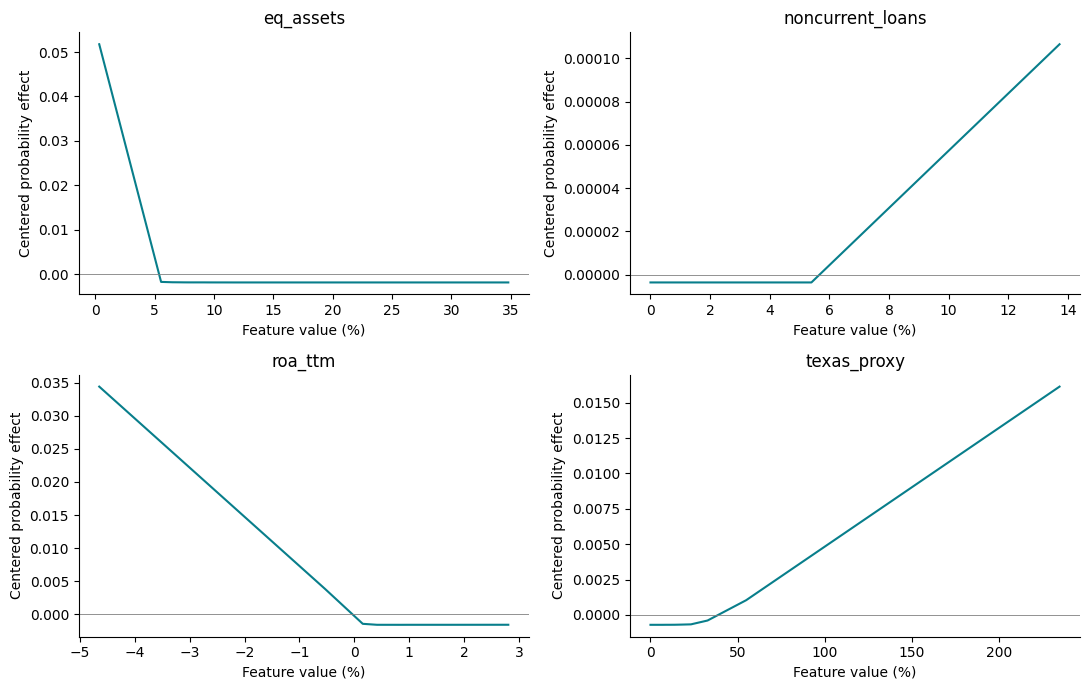

SHAP additivity max error: 1.1102230246251565e-16


In [18]:
shap_summary = read("final_B3_shap.csv")
shap_summary.head(12).sort_values("mean_abs_SHAP_probability").plot.barh(x="feature", y="mean_abs_SHAP_probability", color="#087e8b", legend=False, figsize=(9, 5))
plt.xlabel("Mean |SHAP| · probability scale"); plt.title("B3 associations in a development training sample"); plt.tight_layout(); plt.savefig(FIGURES / "B3_SHAP.png", dpi=150); plt.show()
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, feature in zip(axes.ravel(), ["eq_assets", "noncurrent_loans", "roa_ttm", "texas_proxy"]):
    al = read(f"final_B3_ALE_{feature}.csv"); ax.plot(al.edge, al.ale, color="#087e8b"); ax.axhline(0, color="grey", linewidth=.6); ax.set(title=feature, xlabel="Feature value (%)", ylabel="Centered probability effect")
fig.tight_layout(); fig.savefig(FIGURES / "B3_ALE.png", dpi=150); plt.show()
checks = json.loads((TABLES / "explainability_checks.json").read_text())
print("SHAP additivity max error:", checks["final_model_SHAP_additivity_max_abs_error"])

## 13. Conclusions and transfer to Vietnam
**Q1 — storage and processing:** typed, compressed Parquet and lazy Polars are practical for this panel on a laptop. The measured benchmark and matching Spark plan support the design; a cluster is justified by workload and memory constraints, not the word “big”.

**Q2 — quality:** the pipeline separates accounting semantics, suspicious values, structural gaps and model imputation. Reversible ledgers and exact-quarter joins make changes reviewable. Revised data, historical quarantine and snapshot-based exit evidence limit point-in-time claims.

**Q3 — modelling:** data support honestly separated development and holdout evaluation, but model complexity did not ensure better generalization. The final comparison exposes a stronger simple-reference AP and a large false-alert workload. Cost preferences remain hypothetical and require operational validation.

For Vietnam, replace US Call Report definitions with SBV/local accounting mappings, obtain publication vintages and event definitions, validate local ownership/funding structures, and estimate reviewer time/capacity from workflow logs. US coefficients, thresholds and proxy fees should not be transferred unchanged.

## 14. Reproducibility and source trail
- **Fast review:** Run All in this notebook reads committed aggregate evidence and regenerates figures. No data download, fit or test access occurs.
- **Scientific implementation:** `src/fdic_risk/rules.py`, `pipeline.py`, `policy.py`, `backtest.py`, `benchmarks.py`, `explain.py`.
- **From raw:** see README for acquisition, the explicit expensive dev-backtest replay and private final-fit workflow. Fresh downloads can differ because source values are revised.
- **Checks:** train-only preprocessing, boundary ties, event deduplication, repeat chains, undefined metrics, feature parity, engine parity, model reload and SHAP additivity.
- **Integrity:** `docs/evidence_manifest.json`, `rule_provenance.json`, `frozen_test_protocol.json` and aggregate run manifests.
- **Research limits:** repeated adaptive development comparisons can create selection bias. Neither bootstrap intervals nor a clean rerun erase it. The holdout was not used to improve this release.
- **AI disclosure:** Claude and OpenAI Codex assisted research, implementation and review; authorship remains the student's responsibility. All claims should be understood and defensible at interview.

References and direct links are listed in `references/README.md`. Repository: https://github.com/khanhnlmneuron6-hue/fdic-bank-failure-risk-analytics. Published aggregate inputs are restored from results/summary_tables.zip; bank-level datasets are not included.